# CPG properties

ARIEL has seven central pattern generators (CPGs) in
`ariel.simulation.controllers.cpg`. Each is a network of oscillators, one per
joint, and each call of `forward(time)` returns one joint angle per
oscillator. This notebook puts them side by side on the properties a gait
generator needs, with a check at the end of every section:

| Class | Source | Parameters per joint |
|---|---|---|
| `HopfCPG` | Righetti and Ijspeert, ICRA 2006, eq. 1-2, with Kuramoto phase coupling | phase, w, amplitude, offset |
| `AdaptiveHopfCPG` | the same paper, eq. 1-3: the frequency learns from an input signal | phase, w, amplitude, offset |
| `PhaseCPG` | Ijspeert et al., Science 2007; CPG-RL (2022); Raj and Kos (2026), eq. 1-2 | phase, w, amplitude, offset |
| `SwingStanceCPG` | Righetti and Ijspeert, ICRA 2008, eq. 1-5 | phase, w_swing, w_stance, amplitude, offset |
| `NaCPG` | Tong et al., 2022 (NA-CPG) | phase, w, amplitude, ha (asymmetry), b (offset) |
| `TegotaeCPG` | Owaki et al.; Herneth et al., ICRA 2023, eq. 1, 2, 5: touch steers the phase | phase, w, amplitude, offset, sigma (feedback gain) |
| `LearnableTegotaeCPG` | Herneth et al., ICRA 2023, eq. 3-5: the feedback is three small learned networks | phase, w, amplitude, offset, plus 51 network weights shared by all joints |

The two Tegotae models take a load per joint through `set_input` (the force
the limb feels). With no load they are plain phase oscillators; section 6
shows what the load does.

Throughout, `w` is in rad/s, so `w = 2 pi` is one cycle per second.

In [1]:
# Standard library
import math

# Third-party libraries
import matplotlib.pyplot as plt
import numpy as np
import torch
from rich.console import Console

# Local libraries
from ariel.simulation import (
    AdaptiveHopfCPG,
    HopfCPG,
    LearnableTegotaeCPG,
    NaCPG,
    PhaseCPG,
    SwingStanceCPG,
    TegotaeCPG,
    create_fully_connected_adjacency,
)

%matplotlib inline
plt.rcParams["figure.dpi"] = 50
console = Console()

MODELS = [
    HopfCPG,
    AdaptiveHopfCPG,
    PhaseCPG,
    SwingStanceCPG,
    NaCPG,
    TegotaeCPG,
    LearnableTegotaeCPG,
]
# Models with an amplitude state that a push can knock off its cycle
WITH_A_CYCLE = [HopfCPG, AdaptiveHopfCPG, PhaseCPG, SwingStanceCPG, NaCPG]
OMEGA = 2 * math.pi  # 1 Hz
DT = 0.01


def unit(model, n=1, phases=None):
    """Build a network at 1 Hz, amplitude 1, no offset, no angle limits.

    Returns
    -------
    CPG
        The network, reset to its start state.
    """
    cpg = model(
        create_fully_connected_adjacency(n),
        seed=0,
        angle_limits=None,
        angle_tracking=True,
    )
    values = {
        "phase": phases if phases is not None else [0.0] * n,
        "amplitudes": [1.0] * n,
    }
    for name in cpg.parameter_groups:
        if name.startswith("w"):
            values[name] = [OMEGA] * n
        elif name in {"offset", "b", "ha"}:
            values[name] = [0.0] * n
    cpg.set_param_with_dict(values)
    cpg.reset_state()
    return cpg


def run(cpg, seconds, start=0.0):
    """Call the network every DT seconds of simulated time.

    Returns
    -------
    np.ndarray
        Every angle the network has output since its last reset.
    """
    for step in range(round(seconds / DT) + 1):
        cpg.forward(start + step * DT)
    return np.array(cpg.angle_history)


def upward_crossings(signal):
    return int(((signal[:-1] < 0) & (signal[1:] >= 0)).sum())

## 1. Same settings, five rhythms

Every model gets one joint at 1 Hz with amplitude 1, run for 4 s, with no
load on the Tegotae models. They should
all make the same cycle: four periods between -1 and 1. `PhaseCPG` starts at
zero amplitude and grows into the cycle on purpose; `NaCPG` overshoots the
amplitude by a few percent (the paper reports 5.3 % at its default gain).

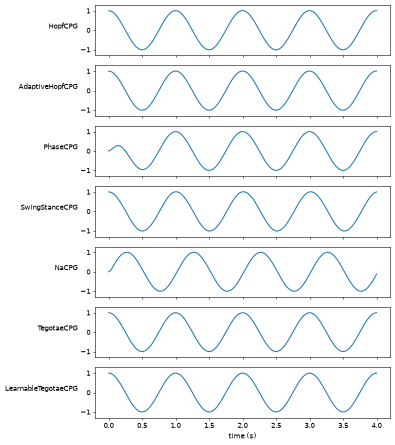

HopfCPG          max +1.010  min -1.010  cycles: 3

AdaptiveHopfCPG  max +1.010  min -1.010  cycles: 3

PhaseCPG         max +1.000  min -1.000  cycles: 3

SwingStanceCPG   max +1.011  min -1.011  cycles: 3

NaCPG            max +1.003  min -1.003  cycles: 3

TegotaeCPG       max +1.000  min -1.000  cycles: 3

LearnableTegotaeCPG max +1.000  min -1.000  cycles: 3

In [2]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(8, 9), sharex=True)
summary = {}
for ax, model in zip(axes, MODELS, strict=True):
    history = run(unit(model), 4.0)[:, 0]
    times = np.arange(len(history)) * DT
    ax.plot(times, history)
    ax.set_ylabel(model.__name__, rotation=0, ha="right")
    ax.set_ylim(-1.3, 1.3)
    settled = history[100:]
    summary[model.__name__] = (
        settled.max(),
        settled.min(),
        upward_crossings(settled),
    )
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()

for name, (high, low, cycles) in summary.items():
    console.print(
        f"{name:16s} max {high:+.3f}  min {low:+.3f}  cycles: {cycles}"
    )

In [3]:
AMPLITUDE_TOLERANCE = 0.06
CYCLES_IN_3_S = {2, 3, 4}
for name, (high, low, cycles) in summary.items():
    assert abs(high - 1) < AMPLITUDE_TOLERANCE, name
    assert abs(low + 1) < AMPLITUDE_TOLERANCE, name
    assert cycles in CYCLES_IN_3_S, name

## 2. The clock follows the simulation

`Controller` calls its callback every 50 physics steps by default, which is
every 0.125 s of simulated time. Each CPG integrates over the time that passed
since its last call, in sub-steps of at most `dt`, so it makes the same 10
cycles in 10 s whether it is called every 0.01 s or every 0.125 s. (Before
this package, the NA-CPG moved 0.01 s per call whatever the gap, and ran 12.5
times too slowly inside a simulation.)

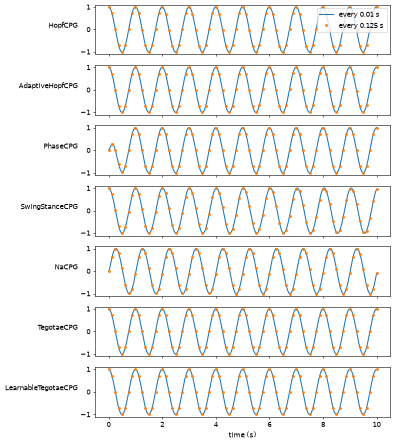

{
    'HopfCPG': (10, 10),
    'AdaptiveHopfCPG': (10, 10),
    'PhaseCPG': (10, 10),
    'SwingStanceCPG': (10, 10),
    'NaCPG': (9, 9),
    'TegotaeCPG': (10, 10),
    'LearnableTegotaeCPG': (10, 10)
}

In [4]:
fig, axes = plt.subplots(len(MODELS), 1, figsize=(8, 9), sharex=True)
cycles = {}
for ax, model in zip(axes, MODELS, strict=True):
    fine = run(unit(model), 10.0)[:, 0]
    coarse_cpg = unit(model)
    coarse = np.array([
        coarse_cpg.forward(k * 0.125)[0].item() for k in range(81)
    ])
    ax.plot(np.arange(len(fine)) * DT, fine, label="every 0.01 s")
    ax.plot(
        np.arange(81) * 0.125, coarse, "o", markersize=3, label="every 0.125 s"
    )
    ax.set_ylabel(model.__name__, rotation=0, ha="right")
    cycles[model.__name__] = (upward_crossings(fine), upward_crossings(coarse))
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()
console.print(cycles)

In [5]:
CYCLES_IN_10_S = range(9, 12)
for name, (fine, coarse) in cycles.items():
    assert fine in CYCLES_IN_10_S, name
    assert coarse in CYCLES_IN_10_S, name

## 3. Phase locking

Three joints start in phase, but their target phases are 0, 1.0 and 2.5 rad.
Only the coupling can pull them apart. After 10 s we measure the phase of each
joint's 1 Hz component. Hopf, adaptive Hopf, phase and NA-CPG all reach the
targets. The two Tegotae models stay in phase on purpose: their oscillators
are not wired to each other (`coupling = 0`, as in the papers), and the
body's loads are what sets their phases apart (section 6). `SwingStanceCPG` cannot: its coupling (`k_ij = h cos(phi_i - phi_j)`,
generalised from the paper's +1/-1 gait matrices) holds only in-phase and
anti-phase pairs, so it settles somewhere else. That matters for gaits that
need a quarter-cycle lag between legs, such as the walk.

In [6]:
TARGETS = [0.0, 1.0, 2.5]


def phase_of(signal):
    times = np.arange(len(signal)) * DT
    return float(np.angle(np.sum(signal * np.exp(-1j * OMEGA * times))))


measured = {}
for model in MODELS:
    cpg = unit(model, 3)
    cpg.set_params_by_group("phase", TARGETS)  # the state stays in phase
    for _ in range(1000):
        cpg.forward()
    history = np.array(cpg.angle_history)[-200:]
    phases = [phase_of(history[:, i]) for i in range(3)]
    measured[model.__name__] = [
        (phases[i] - phases[0]) % (2 * math.pi) for i in range(1, 3)
    ]
    console.print(
        f"{model.__name__:16s} joint 1: {measured[model.__name__][0]:.2f}"
        f" (target 1.00)   joint 2: {measured[model.__name__][1]:.2f}"
        " (target 2.50)"
    )

HopfCPG          joint 1: 1.00 (target 1.00)   joint 2: 2.50 (target 2.50)

AdaptiveHopfCPG  joint 1: 1.00 (target 1.00)   joint 2: 2.50 (target 2.50)

PhaseCPG         joint 1: 1.00 (target 1.00)   joint 2: 2.50 (target 2.50)

SwingStanceCPG   joint 1: 5.91 (target 1.00)   joint 2: 4.87 (target 2.50)

NaCPG            joint 1: 1.00 (target 1.00)   joint 2: 2.50 (target 2.50)

TegotaeCPG       joint 1: 0.00 (target 1.00)   joint 2: 0.00 (target 2.50)

LearnableTegotaeCPG joint 1: 0.00 (target 1.00)   joint 2: 0.00 (target 2.50)

In [7]:
PHASE_TOLERANCE = 0.1
for name, (first, second) in measured.items():
    reaches = (
        abs(first - TARGETS[1]) < PHASE_TOLERANCE
        and abs(second - TARGETS[2]) < PHASE_TOLERANCE
    )
    holds = name not in {
        SwingStanceCPG.__name__,
        TegotaeCPG.__name__,
        LearnableTegotaeCPG.__name__,
    }
    assert reaches == holds, name

## 4. Recovery after a push

The Tegotae models have only a phase and a fixed amplitude, so there is no
cycle to knock them off; they are left out here. At t = 2 s we knock each
other oscillator off its cycle: the Hopf-type models are
moved to a fifth of their radius, the phase model's amplitude is set to 0.2.
A limit cycle pulls the output back. We follow the radius of each oscillator's
state (the amplitude `r` for the phase model) and measure how long it takes
to come back within 5 % of 1.

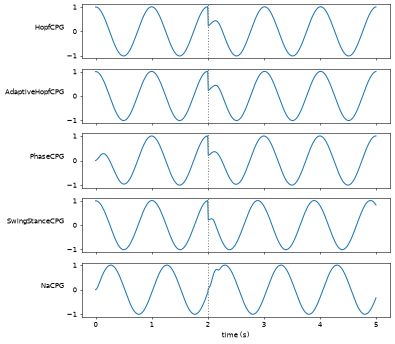

HopfCPG          back within 5 % after about 0.26 s

AdaptiveHopfCPG  back within 5 % after about 0.26 s

PhaseCPG         back within 5 % after about 0.46 s

SwingStanceCPG   back within 5 % after about 0.12 s

NaCPG            back within 5 % after about 0.10 s

In [8]:
def push(cpg):
    # The state was made in inference mode, so it changes in place there
    with torch.inference_mode():
        if isinstance(cpg, PhaseCPG):
            cpg.r *= 0.2
            cpg.r_dot *= 0.0
        elif isinstance(cpg, NaCPG):
            centre = torch.stack([torch.zeros(cpg.n), cpg.b.data], dim=1)
            cpg.xy = centre + 0.2 * (cpg.xy - centre)
        else:
            cpg.xy *= 0.2


def radius(cpg):
    """Return the distance of oscillator 0's state from its centre.

    Returns
    -------
    float
        1 on the limit cycle.
    """
    if isinstance(cpg, PhaseCPG):
        return cpg.r[0].item()
    if isinstance(cpg, NaCPG):
        return math.hypot(
            cpg.xy[0, 0].item(), cpg.xy[0, 1].item() - cpg.b[0].item()
        )
    return math.hypot(cpg.xy[0, 0].item(), cpg.xy[0, 1].item())


BACK = 0.05  # within 5 % of the cycle
recovery = {}
fig, axes = plt.subplots(len(WITH_A_CYCLE), 1, figsize=(8, 7), sharex=True)
for ax, model in zip(axes, WITH_A_CYCLE, strict=True):
    cpg = unit(model)
    run(cpg, 2.0)
    push(cpg)
    radii = []
    for step in range(1, 301):
        cpg.forward(2.0 + step * DT)
        radii.append(radius(cpg))
    history = np.array(cpg.angle_history)[:, 0]
    times = np.arange(len(history)) * DT
    ax.plot(times, history)
    ax.axvline(2.0, color="grey", linestyle=":")
    ax.set_ylabel(model.__name__, rotation=0, ha="right")
    back = next(i for i, r in enumerate(radii) if abs(r - 1) < BACK)
    recovery[model.__name__] = (back + 1) * DT
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()
for name, seconds in recovery.items():
    console.print(f"{name:16s} back within 5 % after about {seconds:.2f} s")

In [9]:
RECOVERY_SECONDS = (0.05, 0.6)
for name, seconds in recovery.items():
    assert RECOVERY_SECONDS[0] < seconds < RECOVERY_SECONDS[1], name

## 5. Smooth changes of frequency and amplitude

At t = 2.125 s (an eighth of a cycle in, so no output sits at zero) each
network gets twice the frequency and half the amplitude. A
good gait generator changes its output smoothly: no step much larger than
what the new cycle itself makes in 0.01 s (2 Hz at amplitude 1 moves at most
`2 pi 2 0.01 = 0.126`).

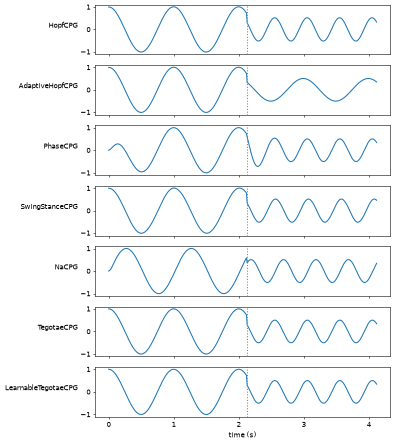

{
    'HopfCPG': np.float64(0.435),
    'AdaptiveHopfCPG': np.float64(0.4),
    'PhaseCPG': np.float64(0.146),
    'SwingStanceCPG': np.float64(0.457),
    'NaCPG': np.float64(0.226),
    'TegotaeCPG': np.float64(0.435),
    'LearnableTegotaeCPG': np.float64(0.435)
}

In [10]:
largest = {}
fig, axes = plt.subplots(len(MODELS), 1, figsize=(8, 9), sharex=True)
for ax, model in zip(axes, MODELS, strict=True):
    cpg = unit(model)
    run(cpg, 2.125)
    frequency_groups = [g for g in cpg.parameter_groups if g.startswith("w")]
    cpg.set_param_with_dict(
        {g: [2 * OMEGA] for g in frequency_groups} | {"amplitudes": [0.5]}
    )
    for step in range(1, 201):
        cpg.forward(2.125 + step * DT)
    history = np.array(cpg.angle_history)[:, 0]
    ax.plot(np.arange(len(history)) * DT, history)
    ax.axvline(2.125, color="grey", linestyle=":")
    ax.set_ylabel(model.__name__, rotation=0, ha="right")
    largest[model.__name__] = np.abs(np.diff(history)).max()
axes[-1].set_xlabel("time (s)")
fig.tight_layout()
plt.show()
console.print({name: round(step, 3) for name, step in largest.items()})

The Hopf-type models, the swing-stance model, the NA-CPG and the two Tegotae
models halve their output at once, because the amplitude is only a factor on the output: the
jump is half the angle at that moment, 0.23 to 0.46 here (the NA-CPG
started from rest and lags a little, so its angle was smaller). `PhaseCPG` glides to the new amplitude through its second-order
amplitude equation and is the only one without a jump: its largest step,
about 0.15, is the 2 Hz cycle's own slope plus the glide. `AdaptiveHopfCPG`
keeps its old frequency: its frequency is a state that only the input or a
reset changes, so setting `w` mid-run has no effect until the next episode.

In [11]:
GLIDE = 0.16  # the 2 Hz cycle's own slope plus the amplitude glide
JUMP = (0.2, 0.5)
assert largest[PhaseCPG.__name__] < GLIDE
for model in MODELS:
    if model is not PhaseCPG:
        assert JUMP[0] < largest[model.__name__] < JUMP[1], model.__name__

## 6. What only one model can do

* `SwingStanceCPG`: with `w_swing = 3 w_stance` the joint spends 3/4 of each
  cycle in stance (`y > 0`) and the cycle keeps its shape.
* `NaCPG`: the asymmetry `ha = 0.4` makes one half of the cycle take about
  `(1 - 0.4) / 2 = 30 %` of the period (33 % measured: the derivative
  constraint slows the switch between the halves).
* `AdaptiveHopfCPG`: fed a 1.5 Hz sine through `set_input`, its frequency
  drifts from 1 Hz to 1.5 Hz and stays there once the input stops.

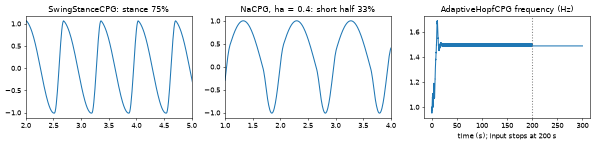

stance 0.751, short half 0.326, learned 1.488 Hz

In [12]:
swing = unit(SwingStanceCPG)
swing.set_param_with_dict({"w_swing": [3 * OMEGA], "w_stance": [OMEGA]})
swing.reset_state()
stance = []
for step in range(1, 1001):
    swing.forward(step * DT)
    stance.append(swing.xy[0, 1].item() > 0)
stance_share = float(np.mean(stance[200:]))

na = unit(NaCPG)
na.set_params_by_group("ha", [0.4])
na.reset_state()
na_history = run(na, 4.0)[100:, 0]
short_half = float((na_history < 0).mean())

adaptive = AdaptiveHopfCPG({0: []}, epsilon=2.0, angle_limits=None)
adaptive.set_param_with_dict({
    "phase": [0.0],
    "w": [OMEGA],
    "amplitudes": [1.0],
    "offset": [0.0],
})
INPUT_ENDS = 200  # seconds
learned = []
for step in range(30_001):
    time = step * DT
    teaching = math.sin(2 * math.pi * 1.5 * time) if time < INPUT_ENDS else 0.0
    adaptive.set_input([teaching])
    adaptive.forward(time)
    learned.append(adaptive.frequency.item() / (2 * math.pi))

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
swing_history = np.array(swing.angle_history)[:, 0]
axes[0].plot(np.arange(len(swing_history)) * DT, swing_history)
axes[0].set_title(f"SwingStanceCPG: stance {stance_share:.0%}")
axes[0].set_xlim(2, 5)
axes[1].plot(np.arange(len(na_history)) * DT + 1, na_history)
axes[1].set_title(f"NaCPG, ha = 0.4: short half {short_half:.0%}")
axes[1].set_xlim(1, 4)
axes[2].plot(np.arange(len(learned)) * DT, learned)
axes[2].axvline(INPUT_ENDS, color="grey", linestyle=":")
axes[2].set_title("AdaptiveHopfCPG frequency (Hz)")
axes[2].set_xlabel("time (s); input stops at 200 s")
fig.tight_layout()
plt.show()
console.print(
    f"stance {stance_share:.3f}, short half {short_half:.3f},"
    f" learned {learned[-1]:.3f} Hz"
)

In [13]:
# (expected value, tolerance)
STANCE_SHARE = (0.75, 0.02)
SHORT_HALF = (0.30, 0.04)
TEACHING_HZ = (1.5, 0.05)
assert abs(stance_share - STANCE_SHARE[0]) < STANCE_SHARE[1]
assert abs(short_half - SHORT_HALF[0]) < SHORT_HALF[1]
assert abs(learned[-1] - TEACHING_HZ[0]) < TEACHING_HZ[1]

## 7. Tegotae: the body sets the rhythm

A limb that is down every other half cycle at the body's own rhythm gives a
load of 5 N (`N = 5 max(0, -sin(2 pi f_body t))`). The 1 Hz `TegotaeCPG`
reads it through `set_input`. With the gain `sigma = 2` the oscillator gives
up its own 1 Hz and follows a body at 0.8 or 1.2 Hz; with `sigma = 0.5` the
pull is too weak and it stays near 1 Hz; with `sigma = 0` the body has no say.
This entrainment is how Tegotae coordinates legs without wiring between their
oscillators.

`LearnableTegotaeCPG` starts with random networks, so its untrained response to
the load is arbitrary; the check here is only that a limb with no load gets no
feedback (`R(N) - R(0)` is 0 at `N = 0`). Training happens in
`cpg_locomotion`.

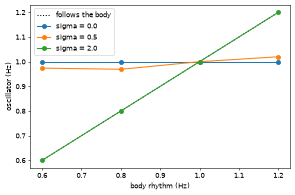

sigma 0.0: 1.000, 1.000, 1.000, 1.000

sigma 0.5: 0.974, 0.969, 1.000, 1.020

sigma 2.0: 0.600, 0.800, 1.000, 1.200

learnable feedback: no load 0.0, 5 N 0.334 rad/s

In [14]:
def follow_body(sigma, body_hz):
    """Run a 1 Hz TegotaeCPG under a body that touches down at body_hz.

    Returns
    -------
    float
        The oscillator's mean frequency over the last 15 of 30 s, in Hz.
    """
    cpg = unit(TegotaeCPG)
    cpg.set_params_by_group("sigma", [sigma])
    phases = []
    for step in range(3001):
        time = step * DT
        down = max(0.0, -math.sin(2 * math.pi * body_hz * time))
        cpg.set_input([5.0 * down])
        cpg.forward(time)
        phases.append(cpg.theta.item())
    return (phases[-1] - phases[1500]) / (15 * 2 * math.pi)


BODIES = [0.6, 0.8, 1.0, 1.2]
GAINS = [0.0, 0.5, 2.0]
followed = {
    sigma: [follow_body(sigma, body_hz) for body_hz in BODIES]
    for sigma in GAINS
}
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(BODIES, BODIES, "k:", label="follows the body")
for sigma, rates in followed.items():
    ax.plot(BODIES, rates, "o-", label=f"sigma = {sigma}")
ax.set_xlabel("body rhythm (Hz)")
ax.set_ylabel("oscillator (Hz)")
ax.legend()
fig.tight_layout()
plt.show()
for sigma, rates in followed.items():
    console.print(
        f"sigma {sigma}: " + ", ".join(f"{rate:.3f}" for rate in rates)
    )

learnable = LearnableTegotaeCPG(create_fully_connected_adjacency(3), seed=0)
learnable.set_input([0.0, 0.0, 0.0])
no_load = learnable.feedback().abs().max().item()
learnable.set_input([5.0, 5.0, 5.0])
with_load = learnable.feedback().abs().max().item()
console.print(
    f"learnable feedback: no load {no_load}, 5 N {with_load:.3f} rad/s"
)

In [15]:
FOLLOWS = 0.01  # Hz
for body_hz, rate in zip(BODIES, followed[2.0], strict=True):
    assert abs(rate - body_hz) < FOLLOWS, body_hz
assert all(abs(rate - 1.0) < FOLLOWS for rate in followed[0.0])
assert math.isclose(no_load, 0.0, abs_tol=1e-12)
assert with_load > 0.0

## Summary

| Property | Hopf | Adaptive Hopf | Phase | Swing-stance | NA-CPG | Tegotae | Learnable Tegotae |
|---|---|---|---|---|---|---|---|
| Set frequency and amplitude | yes | yes | yes (grows from 0) | yes | yes (+4 %) | yes | yes |
| Follows simulation time | yes | yes | yes | yes | yes | yes | yes |
| Holds any phase difference | yes | yes | yes | only 0 and half a cycle | yes | no wiring (the body decides) | no wiring |
| Returns to its cycle after a push | yes | yes | yes | yes | yes | no amplitude state | no amplitude state |
| Amplitude change without a jump | no | no | yes | no | no | no | no |
| Swing and stance timed apart | no | no | no | yes | yes (ha) | by touch | by touch |
| Frequency follows the body | no | from an input signal | no | no | no | yes (sigma) | learned |

`cpg_locomotion` (marked slow) tests all seven on the gecko.